# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB14 — The Effect-Size Circuit, and Faithfulness of Every Possible Circuit

**Track B · Follow-up to MB06–MB12 · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | MB10's rule took every significant component and returned 11 of 12. Does the smaller circuit that MB06 found when an effect-size floor is added (the embedding and the four MLPs, no heads) reproduce the behaviour, and how does it rank among **every** circuit of the same size? |
| **Why** | With 12 components there are only 2^12 = 4,096 possible circuits. Instead of 100 random circuits, every one of them can be scored, so each named circuit gets an exact rank instead of an estimate. |
| **Behaviours** | (1) identity effect: Δ with the player minus Δ with the player removed; (2) arbitration: Δ itself; (3) context effect: Δ in the event's own window minus Δ in the donor window with the event's player written in (MB06 contrast) |
| **Population** | P-player validation. Subsets are **chosen on the discovery half** and **scored on the estimation half**. Matched controls and index-0 rows are used for specificity. |
| **Status** | Follow-up analysis, written after MB12. Not part of the MB12 lock. The plan below is written and fingerprinted before any number is computed. No test data. |
| **Outputs** | `config/MB14_plan.json`, `results/MB14_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import itertools

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 79 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


## 1. Terms

| Term | Meaning here |
|---|---|
| **Circuit S** | A set of heads and MLPs. "Running S" means every component *not* in S is mean-ablated at every position (MB11's definition); the embedding is always kept. |
| **Faithfulness F(S)** | Pooled, sign-aligned (m_S − m_empty) / (m_full − m_empty), as in MB11. 1 = S alone behaves like the model; 0 = like the model with every component removed. |
| **Same-size circuits** | All circuits with the same number of components. The effect-size circuit is ranked among them: if it beats nearly all of them, the specific components matter, not only their number. |
| **Composition class** | All circuits with the same numbers of heads and of MLPs; reported as a secondary comparison. |
| **Effect-size circuit** | The components behind MB06's sensitivity list "q 0.05 and pooled recovery ≥ 0.10", which MB06 saved to `candidates.json` before the estimation half was read. |

## 2. The plan (written before any number)

In [4]:
PLAN = {
    "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
    "circuits_named": ["effect-size circuit from candidates.json sensitivity list (q 0.05 and R >= 0.10)",
                       "pre-registered circuit from circuit.json", "all 8 heads", "all 4 MLPs"],
    "subset_space": "all 2**12 subsets of the 12 heads and MLPs; complement mean-ablated at every position",
    "behaviours": ["identity effect (player -> 0 at the target)", "arbitration (Delta)",
                   "context effect (own window vs MB02 donor window with the event's player written in)"],
    "selection": "best subset of each size and composition is chosen on the DISCOVERY half only",
    "estimate": "every reported F is computed on the ESTIMATION half; intervals from 2,000 match resamples",
    "rank_rule": ("a named circuit's rank is its percentile among all circuits with the same number of components "
                  "(primary) and among circuits with the same numbers of heads and MLPs (secondary; not read when "
                  "that class has a single member), estimation half"),
    "reading_rule": ("the effect-size circuit is called sufficient for a behaviour if its estimation-half F CI "
                     "lies above 0.8, and distinctive if it also ranks above the 95th percentile of all circuits "
                     "of its size"),
    "specificity": "F of the circuit for Delta on matched controls vs on their conflict partners (paired by match)",
    "replication": "F and class rank of the effect-size circuit for seeds 100-104 (estimation half)",
    "robustness": "resample ablation (n_draws draws) for the effect-size circuit and the discovery-selected best subsets"
}
plan_path = OUT / "config" / "MB14_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB14_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan already written at 2026-10-07T17:35:51.111886+00:00 - unchanged
{
 "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
 "circuits_named": [
  "effect-size circuit from candidates.json sensitivity list (q 0.05 and R >= 0.10)",
  "pre-registered circuit from circuit.json",
  "all 8 heads",
  "all 4 MLPs"
 ],
 "subset_space": "all 2**12 subsets of the 12 heads and MLPs; complement mean-ablated at every position",
 "behaviours": [
  "identity effect (player -> 0 at the target)",
  "arbitration (Delta)",
  "context effect (own window vs MB02 donor window with the event's player written in)"
 ],
 "selection": "best subset of each size and composition is chosen on the DISCOVERY half only",
 "estimate": "every reported F is computed on the ESTIMATION half; intervals from 2,000 match resamples",
 "rank_rule": "a named circuit's rank is its percentile among all circuits with the same number of components (primary) and among circuits with the same numbers of heads and M

## 3. The named circuits

The effect-size circuit is read from `candidates.json`. An `mlp_out` site gives that MLP, a head site gives that head, an `attn_out` site gives both heads of its layer; the embedding and residual-stream sites name no component (the embedding is never ablated).

In [5]:
candidates = mi_setup.load_json(OUT / "config" / "candidates.json")
circuit_file = mi_setup.load_json(OUT / "config" / "circuit.json")
sensitivity_key = [key for key in candidates["sensitivity"] if "pooled recovery" in key][0]


def to_components(items):
    chosen = set()
    for item in items:
        parts = item["site"].split()
        if item["site"] == "embedding" or "resid" in item["site"]:
            continue
        layer = int(parts[0][1:])
        if parts[1] == "mlp_out":
            chosen.add(f"L{layer}MLP")
        elif parts[1] == "attn_out":
            chosen.update(f"L{layer}H{head}" for head in range(N_HEADS))
        elif parts[1] == "head":
            chosen.add(f"L{layer}H{parts[2]}")
    return [component for component in ALL if component in chosen]


EFFECT_CIRCUIT = to_components(candidates["sensitivity"][sensitivity_key])
PREREG_CIRCUIT = [component for component in ALL if component in circuit_file["components"]]
HEADS_ONLY = [component for component in ALL if not component.endswith("MLP")]
MLPS_ONLY = [component for component in ALL if component.endswith("MLP")]
NAMED = {"effect-size circuit": EFFECT_CIRCUIT, "pre-registered circuit (MB10)": PREREG_CIRCUIT,
         "all heads, no MLP": HEADS_ONLY, "all MLPs, no head": MLPS_ONLY}
print(f"sensitivity list '{sensitivity_key}': {len(candidates['sensitivity'][sensitivity_key])} site-positions")
for name, members in NAMED.items():
    print(f"{name:32s} {len(members):2d} components: {members}")

sensitivity list 'q 0.05 and pooled recovery >= 0.10 (provisional)': 18 site-positions
effect-size circuit               4 components: ['L0MLP', 'L1MLP', 'L2MLP', 'L3MLP']
pre-registered circuit (MB10)    11 components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H1', 'L3MLP']
all heads, no MLP                 8 components: ['L0H0', 'L0H1', 'L1H0', 'L1H1', 'L2H0', 'L2H1', 'L3H0', 'L3H1']
all MLPs, no head                 4 components: ['L0MLP', 'L1MLP', 'L2MLP', 'L3MLP']


## 4. Scoring every subset

For each event the clean run, the player-removed run and (for the context effect) the donor-window run are computed once per subset. Δ of every subset is stored, so every later number is a cheap re-reading of the same arrays. Subsets are encoded as 12-bit masks in the order of the component list.

Running time: 4,096 subsets × 3 runs × (1,744 events / batch) forward passes. On a GPU this takes a few minutes; on a CPU it can take an hour.

In [6]:
N_COMPONENTS = len(ALL)
MASKS = np.arange(2 ** N_COMPONENTS)
FULL_MASK, EMPTY_MASK = 2 ** N_COMPONENTS - 1, 0


def members(mask):
    return [ALL[i] for i in range(N_COMPONENTS) if (mask >> i) & 1]


def mask_of(components):
    return int(sum(1 << ALL.index(component) for component in components))


def composition(mask):
    chosen = members(mask)
    return (sum(1 for c in chosen if not c.endswith("MLP")), sum(1 for c in chosen if c.endswith("MLP")))


def context_inputs(inputs, positions, chunk):
    donor_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy().astype(int))
    return interventions.write_identity(donor_inputs, inputs, positions, ["player"])


@torch.no_grad()
def score_all_subsets(model, means, table, masks, with_context=True, label=""):
    """{run: array [n_masks, n_events]} of Delta under each subset; runs: clean, removed, context."""
    runs = ["clean", "removed"] + (["context"] if with_context else [])
    out = {run: np.full((len(masks), len(table)), np.nan, dtype=np.float32) for run in runs}
    start = time.time()
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        variants = {"clean": inputs, "removed": interventions.remove_feature(inputs, IDENTITY, positions)}
        if with_context:
            has_donor = chunk["donor_window"].notna().to_numpy()
            filled = chunk.assign(donor_window=chunk["donor_window"].fillna(chunk["window"]))
            variants["context"] = context_inputs(inputs, positions, filled)
        for row, mask in enumerate(masks):
            ablated = [c for c in ALL if c not in members(mask)]
            replace = circuits.ablation_edits(ablated, means, None) if ablated else None
            for run, run_inputs in variants.items():
                values = circuits.delta_under(model, run_inputs, positions, a_ctx, a_id, replace)
                if run == "context":
                    values = np.where(has_donor, values, np.nan)
                out[run][row, part] = values
    print(f"{label}: {len(masks)} subsets x {len(table)} events in {time.time() - start:.0f} s")
    return out


scores = {}
for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
    scores[half_name] = score_all_subsets(MODEL, MEANS, table, MASKS, label=f"seed {PRIMARY_SEED}, {half_name}")
np.savez_compressed(OUT / "results" / "MB14_subset_deltas.npz",
                    **{f"{half}_{run}": array for half, runs in scores.items() for run, array in runs.items()},
                    components=np.array(ALL))

seed 103, discovery: 4096 subsets x 1215 events in 597 s


seed 103, estimation: 4096 subsets x 529 events in 357 s


In [7]:
def behaviour_matrix(runs, behaviour):
    if behaviour == "identity effect":
        return runs["clean"] - runs["removed"]
    if behaviour == "arbitration":
        return runs["clean"]
    return runs["clean"] - runs["context"]


BEHAVIOURS = ["identity effect", "arbitration", "context effect"]


def faithfulness_all(runs, behaviour):
    """F of every subset (point values, pooled and sign-aligned as in MB11)."""
    matrix = behaviour_matrix(runs, behaviour).astype(np.float64)
    keep = ~np.isnan(matrix[FULL_MASK])
    full, empty = matrix[FULL_MASK, keep], matrix[EMPTY_MASK, keep]
    sign = np.sign(full - empty)
    bottom = np.abs(full - empty).sum()
    return ((matrix[:, keep] - empty) * sign).sum(axis=1) / bottom


def faithfulness_ci(runs, behaviour, mask, table):
    matrix = behaviour_matrix(runs, behaviour).astype(np.float64)
    keep = ~np.isnan(matrix[FULL_MASK])
    full, empty, value = matrix[FULL_MASK, keep], matrix[EMPTY_MASK, keep], matrix[mask, keep]
    return mi_metrics.pooled_recovery(value - empty, full - empty, table["match_id"].to_numpy()[keep], N_BOOT)


F = {half: {behaviour: faithfulness_all(scores[half], behaviour) for behaviour in BEHAVIOURS} for half in scores}
compositions = np.array([composition(mask) for mask in MASKS])
sizes = compositions.sum(axis=1)
print("subsets per composition class (heads, MLPs): smallest class has",
      pd.Series([tuple(c) for c in compositions]).value_counts().min(), "members")

subsets per composition class (heads, MLPs): smallest class has 1 members


## 5. Named circuits: F and exact rank within their composition class (estimation half)

In [8]:
named_rows = []
for name, components in NAMED.items():
    mask = mask_of(components)
    same_class = np.all(compositions == compositions[mask], axis=1)
    same_size = sizes == sizes[mask]
    for behaviour in BEHAVIOURS:
        result = faithfulness_ci(scores["estimation"], behaviour, mask, estimation)
        value = F["estimation"][behaviour][mask]
        size_values = F["estimation"][behaviour][same_size]
        class_values = F["estimation"][behaviour][same_class]
        named_rows.append({"circuit": name, "components": len(components), "behaviour": behaviour,
                           "F": result["recovery"], "F CI low": result["ci_low"], "F CI high": result["ci_high"],
                           "same-size circuits": int(same_size.sum()),
                           "percentile among same size": float((size_values < value).mean() * 100),
                           "same-size median F": float(np.median(size_values)),
                           "same-size 95th percentile F": float(np.percentile(size_values, 95)),
                           "class (heads, MLPs)": str(tuple(int(v) for v in compositions[mask])),
                           "class size": int(same_class.sum()),
                           "percentile in class": float((class_values < value).mean() * 100) if same_class.sum() > 1 else np.nan})
named = pd.DataFrame(named_rows)
named.to_csv(OUT / "results" / "MB14_named_circuits.csv", index=False)
print(named.round(4).to_string(index=False))

                      circuit  components       behaviour      F  F CI low  F CI high  same-size circuits  percentile among same size  same-size median F  same-size 95th percentile F class (heads, MLPs)  class size  percentile in class
          effect-size circuit           4 identity effect 0.9008    0.8310     1.0120                 495                     99.7980              0.1136                       0.5988              (0, 4)           1                  NaN
          effect-size circuit           4     arbitration 0.9645    0.9531     0.9739                 495                     99.7980              0.1200                       0.4922              (0, 4)           1                  NaN
          effect-size circuit           4  context effect 0.9600    0.9406     0.9832                 495                     99.7980              0.0953                       0.4349              (0, 4)           1                  NaN
pre-registered circuit (MB10)          11 identity effec

**Reading rule (from the plan).** Sufficient: F interval above 0.8. Distinctive: above the 95th percentile of all circuits of the same size. The composition class is shown as well, but a class with one member (for example four MLPs and no head) has nothing to compare with and its percentile is left empty.

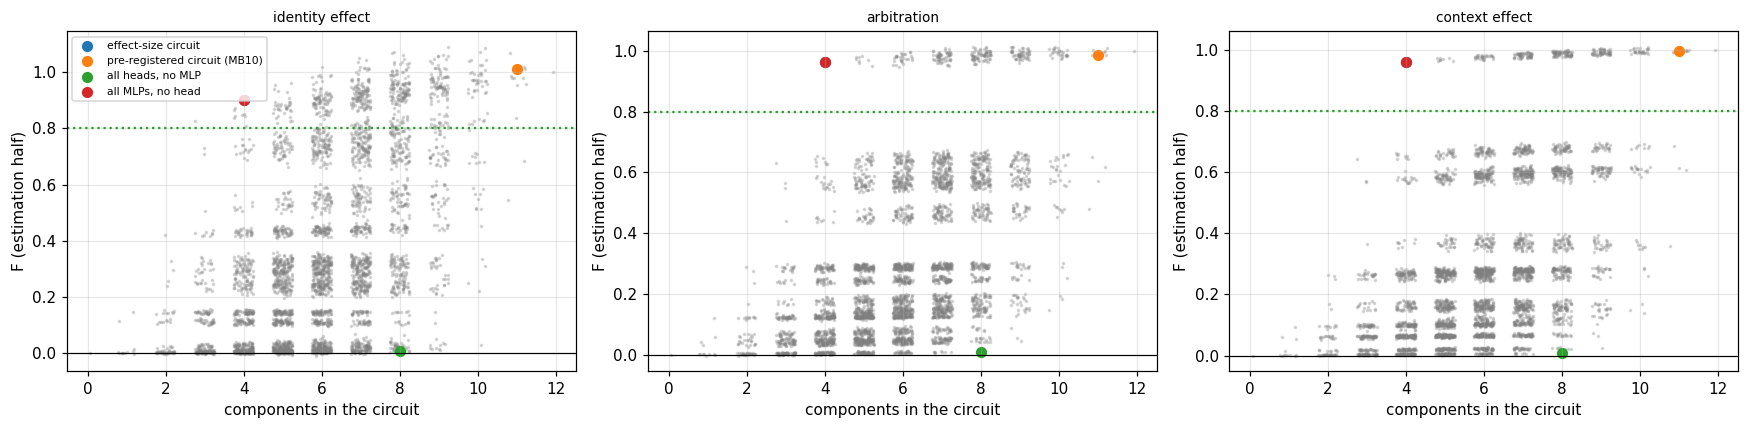

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, behaviour in zip(axes, BEHAVIOURS):
    values = F["estimation"][behaviour]
    axis.scatter(sizes + np.random.default_rng(0).uniform(-0.25, 0.25, len(sizes)), values, s=2, alpha=0.25, color="grey")
    for name, components in NAMED.items():
        mask = mask_of(components)
        axis.scatter([sizes[mask]], [values[mask]], s=40, label=name)
    axis.axhline(0.8, color="tab:green", linestyle=":"); axis.axhline(0, color="black", linewidth=0.8)
    axis.set_xlabel("components in the circuit"); axis.set_ylabel("F (estimation half)"); axis.set_title(behaviour, fontsize=9)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB14_all_subsets.png", bbox_inches="tight"); plt.show()

## 6. The best circuit of each size — chosen on discovery, scored on estimation

For each size k and behaviour, the subset with the highest discovery-half F is taken and its estimation-half F reported. Choosing on discovery and scoring on estimation keeps the "best of 4,096" selection from inflating the number.

In [10]:
best_rows = []
for behaviour in BEHAVIOURS:
    for k in range(N_COMPONENTS + 1):
        in_size = np.where(sizes == k)[0]
        chosen = in_size[np.argmax(F["discovery"][behaviour][in_size])]
        result = faithfulness_ci(scores["estimation"], behaviour, chosen, estimation)
        best_rows.append({"behaviour": behaviour, "size": k, "best subset (chosen on discovery)": "+".join(members(chosen)) or "(none)",
                          "F discovery": float(F["discovery"][behaviour][chosen]), "F estimation": result["recovery"],
                          "CI low": result["ci_low"], "CI high": result["ci_high"],
                          "heads in it": int(compositions[chosen][0]), "MLPs in it": int(compositions[chosen][1])})
best = pd.DataFrame(best_rows)
best.to_csv(OUT / "results" / "MB14_best_by_size.csv", index=False)
print(best.round(4).to_string(index=False))
for behaviour in BEHAVIOURS:
    block = best[(best.behaviour == behaviour) & (best["CI low"] > 0.8)]
    print(f"{behaviour}: smallest discovery-chosen circuit whose estimation F interval is above 0.8: "
          + (f"size {int(block['size'].min())} -> {block.loc[block['size'].idxmin(), 'best subset (chosen on discovery)']}" if len(block) else "none"))

      behaviour  size                               best subset (chosen on discovery)  F discovery  F estimation  CI low  CI high  heads in it  MLPs in it
identity effect     0                                                          (none)       0.0000        0.0000  0.0000   0.0000            0           0
identity effect     1                                                           L0MLP       0.1029        0.1448  0.1085   0.1731            0           1
identity effect     2                                                     L0MLP+L1MLP       0.3201        0.4217  0.3257   0.5214            0           2
identity effect     3                                               L0MLP+L1MLP+L3MLP       0.8103        0.8261  0.6327   0.9908            0           3
identity effect     4                                         L0MLP+L1MLP+L2MLP+L3MLP       0.9575        0.9008  0.8310   1.0120            0           4
identity effect     5                                    L0MLP+L1H1+L1

## 7. Minimality and robustness of the effect-size circuit

Drop one component at a time (estimation half), and repeat the full / circuit / empty runs with resample ablation (`n_draws` draws) instead of mean ablation.

In [11]:
minimal_rows = []
effect_mask = mask_of(EFFECT_CIRCUIT)
for component in EFFECT_CIRCUIT:
    reduced = effect_mask & ~(1 << ALL.index(component))
    for behaviour in BEHAVIOURS:
        result = faithfulness_ci(scores["estimation"], behaviour, reduced, estimation)
        minimal_rows.append({"dropped": component, "behaviour": behaviour, "F without it": result["recovery"],
                             "CI low": result["ci_low"], "CI high": result["ci_high"]})
minimality = pd.DataFrame(minimal_rows)
minimality.to_csv(OUT / "results" / "MB14_minimality.csv", index=False)
print(minimality.round(4).to_string(index=False))


@torch.no_grad()
def resample_faithfulness(components, table, draws, seed=0):
    generator = torch.Generator().manual_seed(seed)
    remove = lambda inputs, positions, chunk: interventions.remove_feature(inputs, IDENTITY, positions)
    runs = {}
    for name, ablated in [("full", []), ("circuit", [c for c in ALL if c not in components]), ("empty", list(ALL))]:
        repeats = []
        for _ in range(draws if ablated else 1):
            builder = circuits.resample_ablation(MODEL, bundle, val_view, REFERENCE_WINDOWS, ablated, False, generator)
            repeats.append(circuits.identity_effects(MODEL, bundle, val_view, table, BATCH, remove, builder))
        runs[name] = (np.mean([r[0] for r in repeats], 0), np.mean([r[1] for r in repeats], 0))
    out = {}
    matches = table["match_id"].to_numpy()
    for behaviour, pick in [("identity effect", lambda pair: pair[0] - pair[1]), ("arbitration", lambda pair: pair[0])]:
        full, circ, empty = pick(runs["full"]), pick(runs["circuit"]), pick(runs["empty"])
        out[behaviour] = mi_metrics.pooled_recovery(circ - empty, full - empty, matches, N_BOOT)
    return out


resample_rows = []
check_set = {"effect-size circuit": EFFECT_CIRCUIT}
for behaviour in ["identity effect", "arbitration"]:
    row = best[(best.behaviour == behaviour) & (best["size"] == len(EFFECT_CIRCUIT))].iloc[0]
    check_set[f"best size-{len(EFFECT_CIRCUIT)} subset for {behaviour}"] = row["best subset (chosen on discovery)"].split("+")
for name, components in check_set.items():
    result = resample_faithfulness(components, estimation, N_DRAWS)
    for behaviour, value in result.items():
        resample_rows.append({"circuit": name, "components": "+".join(components), "behaviour": behaviour,
                              "F (resample ablation)": value["recovery"], "CI low": value["ci_low"], "CI high": value["ci_high"]})
resample_check = pd.DataFrame(resample_rows)
resample_check.to_csv(OUT / "results" / "MB14_resample_check.csv", index=False)
print(resample_check.round(4).to_string(index=False))

dropped       behaviour  F without it  CI low  CI high
  L0MLP identity effect        0.5064  0.4184   0.6111
  L0MLP     arbitration        0.4400  0.3919   0.5075
  L0MLP  context effect        0.3644  0.3053   0.4390
  L1MLP identity effect        0.7286  0.5731   0.9609
  L1MLP     arbitration        0.5637  0.5262   0.5953
  L1MLP  context effect        0.5693  0.5052   0.6460
  L2MLP identity effect        0.8261  0.6327   0.9908
  L2MLP     arbitration        0.6320  0.6069   0.6559
  L2MLP  context effect        0.6431  0.5977   0.6881
  L3MLP identity effect        0.7103  0.6221   0.7874
  L3MLP     arbitration        0.5482  0.5280   0.5635
  L3MLP  context effect        0.5684  0.5420   0.5891


                               circuit              components       behaviour  F (resample ablation)  CI low  CI high
                   effect-size circuit L0MLP+L1MLP+L2MLP+L3MLP identity effect                 0.9770  0.8898   1.0833
                   effect-size circuit L0MLP+L1MLP+L2MLP+L3MLP     arbitration                 0.9082  0.8931   0.9202
best size-4 subset for identity effect L0MLP+L1MLP+L2MLP+L3MLP identity effect                 0.9770  0.8898   1.0833
best size-4 subset for identity effect L0MLP+L1MLP+L2MLP+L3MLP     arbitration                 0.9082  0.8931   0.9202
    best size-4 subset for arbitration L0MLP+L1MLP+L2MLP+L3MLP identity effect                 0.9770  0.8898   1.0833
    best size-4 subset for arbitration L0MLP+L1MLP+L2MLP+L3MLP     arbitration                 0.9082  0.8931   0.9202


## 8. Is the effect-size circuit specific to conflicts?

MB11's specificity compared raw changes in Δ, which a larger starting Δ inflates. Here the comparison is between **shares**: F of the circuit for Δ on the matched non-conflict controls against F on their conflict partners, each normalised by its own full and empty runs. Similar shares mean the circuit carries the model's prediction in general, not something particular to conflicts.

In [12]:
@torch.no_grad()
def three_runs(table, components):
    out = {}
    for name, ablated in [("full", []), ("circuit", [c for c in ALL if c not in components]), ("empty", list(ALL))]:
        builder = circuits.mean_ablation(ablated, MEANS, False) if ablated else None
        out[name] = circuits.deltas(MODEL, bundle, val_view, table, BATCH, builder)
    return out


pairs = controls.merge(p_player[["event_row", "match_id", "half"]], left_on="partner_event_row", right_on="event_row",
                       suffixes=("", "_partner"))
pairs = pairs[pairs["half_partner"] == "estimation"].reset_index(drop=True)
spec_rows = []
if len(pairs):
    partner_table = p_player.set_index("event_row").loc[pairs["partner_event_row"]].reset_index()
    runs_control = three_runs(pairs, EFFECT_CIRCUIT)
    runs_conflict = three_runs(partner_table, EFFECT_CIRCUIT)
    matches = pairs["match_id_partner"].to_numpy()
    unique = np.unique(matches)
    rng = np.random.default_rng(0)

    def share(runs, rows):
        full, circ, empty = (runs[k][rows] for k in ["full", "circuit", "empty"])
        bottom = np.abs(full - empty).sum()
        return float(((circ - empty) * np.sign(full - empty)).sum() / bottom) if bottom > 0 else np.nan

    every = np.arange(len(pairs))
    point = {"conflicts": share(runs_conflict, every), "controls": share(runs_control, every)}
    draws = []
    for _ in range(N_BOOT):
        chosen = rng.choice(unique, size=len(unique), replace=True)
        rows = np.concatenate([np.where(matches == m)[0] for m in chosen])
        draws.append(share(runs_conflict, rows) - share(runs_control, rows))
    spec_rows.append({"pairs": len(pairs), "F on conflicts": point["conflicts"], "F on controls": point["controls"],
                      "difference": point["conflicts"] - point["controls"],
                      "CI low": float(np.nanpercentile(draws, 2.5)), "CI high": float(np.nanpercentile(draws, 97.5)),
                      "mean Delta full, conflicts": float(runs_conflict["full"].mean()),
                      "mean Delta full, controls": float(runs_control["full"].mean()),
                      "mean Delta empty, conflicts": float(runs_conflict["empty"].mean()),
                      "mean Delta empty, controls": float(runs_control["empty"].mean())})
specificity = pd.DataFrame(spec_rows)
specificity.to_csv(OUT / "results" / "MB14_specificity.csv", index=False)
print(specificity.round(4).T.to_string() if len(specificity) else "no estimation-half pairs")

                                   0
pairs                        65.0000
F on conflicts                1.0041
F on controls                 1.0078
difference                   -0.0037
CI low                       -0.0434
CI high                       0.0207
mean Delta full, conflicts    4.9926
mean Delta full, controls     2.7841
mean Delta empty, conflicts  -6.7225
mean Delta empty, controls   -6.7763


## 9. Replication across the five checkpoints

For each seed, reference means are recomputed on the same 2,000 windows (as in MB11), the effect-size circuit's F is computed on the estimation half, and its rank among all circuits of the same size is recomputed for that seed. MLPs are matched by layer, and the effect-size circuit contains no head, so no head matching is needed.

In [13]:
ablation_sites = [f"{kind}_{l}" for l in range(N_LAYERS) for kind in ["head_z", "mlp_out"]]
same_size_masks = MASKS[sizes == sizes[effect_mask]]
class_masks = np.unique(np.concatenate([same_size_masks, [FULL_MASK, EMPTY_MASK]]))
replication_rows = []
for seed in SEEDS:
    model = MODEL if seed == PRIMARY_SEED else mi_setup.load_model(run_dir(seed), bundle)
    means = MEANS if seed == PRIMARY_SEED else mi_setup.reference_means(model, bundle, val_view, REFERENCE_WINDOWS,
                                                                         ablation_sites, BATCH, hooks.forward)
    runs = score_all_subsets(model, means, estimation, class_masks, label=f"seed {seed}")
    index_of = {int(mask): row for row, mask in enumerate(class_masks)}
    for behaviour in BEHAVIOURS:
        matrix = behaviour_matrix(runs, behaviour).astype(np.float64)
        keep = ~np.isnan(matrix[index_of[FULL_MASK]])
        full, empty = matrix[index_of[FULL_MASK], keep], matrix[index_of[EMPTY_MASK], keep]
        sign, bottom = np.sign(full - empty), np.abs(full - empty).sum()
        class_values = np.array([((matrix[index_of[int(m)], keep] - empty) * sign).sum() / bottom
                                 for m in same_size_masks])
        value = mi_metrics.pooled_recovery(matrix[index_of[effect_mask], keep] - empty, full - empty,
                                           estimation["match_id"].to_numpy()[keep], N_BOOT)
        replication_rows.append({"seed": seed, "behaviour": behaviour, "F": value["recovery"], "CI low": value["ci_low"],
                                 "CI high": value["ci_high"],
                                 "percentile among same size": float((class_values < value["recovery"]).mean() * 100),
                                 "same-size circuits": len(class_values)})
    if seed != PRIMARY_SEED:
        del model
replication = pd.DataFrame(replication_rows)
replication.to_csv(OUT / "results" / "MB14_replication.csv", index=False)
print(replication.round(4).to_string(index=False))

seed 100: 497 subsets x 529 events in 44 s


seed 101: 497 subsets x 529 events in 44 s


seed 102: 497 subsets x 529 events in 44 s


seed 103: 497 subsets x 529 events in 44 s


seed 104: 497 subsets x 529 events in 44 s
 seed       behaviour      F  CI low  CI high  percentile among same size  same-size circuits
  100 identity effect 0.9544  0.8744   1.0182                     97.7778                 495
  100     arbitration 0.9705  0.9578   0.9784                     99.7980                 495
  100  context effect 0.9548  0.9378   0.9703                     99.7980                 495
  101 identity effect 0.9122  0.8158   1.0592                     98.1818                 495
  101     arbitration 0.9654  0.9479   0.9755                     99.7980                 495
  101  context effect 0.9555  0.9264   0.9799                     99.7980                 495
  102 identity effect 0.9888  0.9398   1.0322                     99.5960                 495
  102     arbitration 0.9575  0.9520   0.9643                     99.7980                 495
  102  context effect 0.9231  0.9049   0.9445                     99.7980                 495
  103 identity ef

## 10. Additions from the deep MI audit

The audit (Section 13.3) asked four more questions of the same 4,096 subsets:

1. **How much does each component contribute to each behaviour?** Exact Shapley values, computed from every subset rather than estimated.
2. **Is there a set of components that carries identity but not context, or the reverse?** The "separability circuits".
3. **Which components carry the interaction** (how much the player's effect changes when the context changes)?
4. **Do the answers hold for genuine and coupled events, and for frequent and less frequent players?**

These additions have their own plan, written and fingerprinted before any of their numbers.

In [14]:
PLAN = {
    "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
    "behaviours": ["identity effect", "arbitration", "context effect",
                   "interaction = (clean - removed) - (context - context with the player removed)"],
    "extra_run": "Delta in the donor window with the event's player written in and then removed, under every subset (needed for the interaction)",
    "shapley": ("exact Shapley value of each of the 12 components, with value function v(S) = F(S) on the estimation half; "
                "F(full) = 1 and F(empty) = 0, so the 12 values add up to 1; 95% intervals from 2,000 match resamples "
                "(the same resamples for every behaviour, so differences between behaviours have valid intervals)"),
    "component_reading_rule": ("a component is called identity-dominant if Shapley(identity) - Shapley(context) has a CI above 0.05, "
                               "context-dominant if below -0.05, shared otherwise"),
    "separability": ("S_id = the subset with the largest discovery-half F(identity) - F(context); S_ctx the reverse. "
                     "Both scored on the estimation half"),
    "separability_reading_rule": ("component-level separation is FOUND for a signal if its subset has estimation-half "
                                  "F(own) - F(other) with CI low > 0.25 AND F(own) with CI low > 0.5. If neither signal "
                                  "passes, separation is TESTED AND FOUND ABSENT at component level (all 4,096 subsets searched)"),
    "strata": ["genuine vs coupled", "acting player's training events < 1,000 vs >= 1,000"],
    "strata_reading": "named-circuit F and Shapley values per stratum, estimation half; descriptive"
}
plan_path = OUT / "config" / "MB14_ext_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB14_ext_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB14_ext_plan.json
{
 "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
 "behaviours": [
  "identity effect",
  "arbitration",
  "context effect",
  "interaction = (clean - removed) - (context - context with the player removed)"
 ],
 "extra_run": "Delta in the donor window with the event's player written in and then removed, under every subset (needed for the interaction)",
 "shapley": "exact Shapley value of each of the 12 components, with value function v(S) = F(S) on the estimation half; F(full) = 1 and F(empty) = 0, so the 12 values add up to 1; 95% intervals from 2,000 match resamples (the same resamples for every behaviour, so differences between behaviours have valid intervals)",
 "component_reading_rule": "a component is called identity-dominant if Shapley(identity) - Shapley(context) has a CI above 0.05, context-dominant if below -0.05, shared otherwise",
 "separability": "S_id = the subset with the largest discovery-half F(id

In [15]:
# Per-player facts from the TRAINING split, in the model's own (T300) player indices:
# modal role, modal team, number of training events. Used for frequency bands, role centroids and
# team-matched partners. Nothing here reads validation labels.
ENCODED = bundle["encoded"].tensors
assert len(ENCODED["player"]) == len(events), "BLOCKED: encoded tensors are not one row per event."
assert "split" in events.columns, "BLOCKED: events has no split column, so training counts cannot be computed."
TRAIN_ROWS = np.where(events["split"].to_numpy() == "train")[0]
_train = pd.DataFrame({name: ENCODED[name][torch.as_tensor(TRAIN_ROWS, device=ENCODED[name].device)].cpu().numpy()
                       for name in ["player", "role", "team"]})
_train = _train[_train["player"] > 0]
PLAYER_META = _train.groupby("player").agg(role=("role", lambda s: s.value_counts().index[0]),
                                           team=("team", lambda s: s.value_counts().index[0]),
                                           train_events=("role", "size"))
FREQUENCY_CUT = 1000


def frequency_band(players):
    counts = PLAYER_META["train_events"].reindex(np.asarray(players)).to_numpy()
    return np.where(np.isnan(counts), "no training events",
                    np.where(counts >= FREQUENCY_CUT, f">= {FREQUENCY_CUT} training events", f"< {FREQUENCY_CUT} training events"))


PLAYER_TABLE = MODEL.embedding.embeddings["player"].weight.detach()
ROLE_CENTROID = {int(role): PLAYER_TABLE[torch.as_tensor(group.index.to_numpy(), device=PLAYER_TABLE.device)].mean(0)
                 for role, group in PLAYER_META.groupby("role")}
print(f"players with training events: {len(PLAYER_META)} | roles: {len(ROLE_CENTROID)} | "
      f"frequency bands: {pd.Series(frequency_band(PLAYER_META.index)).value_counts().to_dict()}")


def player_vector_edit(new_vectors, players, positions):
    """Edit for site factor_player: at the scored position, swap the player's own embedding for new_vectors.

    The factor site is the sum of the group's embeddings; subtracting the player's own row and adding the new
    vector changes only the player part, whatever else the group contains."""
    own = PLAYER_TABLE[torch.as_tensor(np.asarray(players), device=PLAYER_TABLE.device)]

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        new[rows, positions] = value[rows, positions] - own.to(value.device) + new_vectors.to(value.device)
        return new
    return edit


def control_vectors(players, kind, rng):
    """Replacement player vectors for the identity controls (rows whose control is undefined get NaN)."""
    players = np.asarray(players)
    out = torch.full((len(players), PLAYER_TABLE.shape[1]), float("nan"), device=PLAYER_TABLE.device)
    for i, player in enumerate(players):
        if player not in PLAYER_META.index:
            continue
        role = int(PLAYER_META.loc[player, "role"])
        centroid = ROLE_CENTROID[role]
        own = PLAYER_TABLE[player]
        if kind == "role centroid":
            out[i] = centroid
        elif kind == "distribution-matched deviation":
            others = PLAYER_META.index[(PLAYER_META["role"] == role) & (PLAYER_META.index != player)
                                       & (PLAYER_META.index != partner_of.get(player, -1))].to_numpy()
            if len(others) == 0:
                continue
            other = PLAYER_TABLE[int(rng.choice(others))] - centroid
            out[i] = centroid + other * (own - centroid).norm() / (other.norm() + 1e-12)
        elif kind == "shuffled coordinates":
            out[i] = own[torch.as_tensor(rng.permutation(len(own)), device=own.device)]
        else:
            raise ValueError(kind)
    return out


def team_matched_partner(player):
    """Same modal role AND team, nearest log training count; -1 if none."""
    if player not in PLAYER_META.index:
        return -1
    row = PLAYER_META.loc[player]
    pool = PLAYER_META[(PLAYER_META["role"] == row["role"]) & (PLAYER_META["team"] == row["team"])
                       & (PLAYER_META.index != player)]
    if len(pool) == 0:
        return -1
    gap = np.abs(np.log(pool["train_events"].to_numpy()) - np.log(row["train_events"]))
    return int(pool.index[np.lexsort((pool.index.to_numpy(), gap))[0]])

players with training events: 350 | roles: 23 | frequency bands: {'< 1000 training events': 333, '>= 1000 training events': 17}


### 10.1 The extra run for the interaction

The interaction behaviour needs one more run per subset: the donor window with the event's own player written in, then removed. This adds a third of the original running time. If the arrays were saved by an earlier run of this section, they are reused.

In [16]:
@torch.no_grad()
def score_context_removed(model, means, table, masks, label=""):
    out = np.full((len(masks), len(table)), np.nan, dtype=np.float32)
    start = time.time()
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        has_donor = chunk["donor_window"].notna().to_numpy()
        filled = chunk.assign(donor_window=chunk["donor_window"].fillna(chunk["window"]))
        run_inputs = interventions.remove_feature(context_inputs(inputs, positions, filled), IDENTITY, positions)
        for row, mask in enumerate(masks):
            ablated = [c for c in ALL if c not in members(mask)]
            replace = circuits.ablation_edits(ablated, means, None) if ablated else None
            values = circuits.delta_under(model, run_inputs, positions, a_ctx, a_id, replace)
            out[row, part] = np.where(has_donor, values, np.nan)
    print(f"{label}: context-removed run, {len(masks)} subsets x {len(table)} events in {time.time() - start:.0f} s")
    return out


extra_path = OUT / "results" / "MB14_subset_deltas_context_removed.npz"
if extra_path.exists():
    stored = np.load(extra_path)
    for half in scores:
        scores[half]["context_removed"] = stored[half]
    print("reused", extra_path.name)
else:
    for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
        scores[half_name]["context_removed"] = score_context_removed(MODEL, MEANS, table, MASKS, f"seed {PRIMARY_SEED}, {half_name}")
    np.savez_compressed(extra_path, **{half: scores[half]["context_removed"] for half in scores})

_old_behaviour_matrix = behaviour_matrix


def behaviour_matrix(runs, behaviour):
    if behaviour == "interaction":
        return (runs["clean"] - runs["removed"]) - (runs["context"] - runs["context_removed"])
    return _old_behaviour_matrix(runs, behaviour)


BEHAVIOURS_EXT = ["identity effect", "context effect", "arbitration", "interaction"]
for half in scores:
    F[half]["interaction"] = faithfulness_all(scores[half], "interaction")
interaction_named = []
for name, components in NAMED.items():
    mask = mask_of(components)
    result = faithfulness_ci(scores["estimation"], "interaction", mask, estimation)
    same_size = F["estimation"]["interaction"][sizes == sizes[mask]]
    interaction_named.append({"circuit": name, "components": len(components), "F (interaction)": result["recovery"],
                              "CI low": result["ci_low"], "CI high": result["ci_high"],
                              "percentile among same size": float((same_size < F["estimation"]["interaction"][mask]).mean() * 100)})
interaction_named = pd.DataFrame(interaction_named)
interaction_named.to_csv(OUT / "results" / "MB14_interaction_named.csv", index=False)
print(interaction_named.round(4).to_string(index=False))

seed 103, discovery: context-removed run, 4096 subsets x 1215 events in 197 s


seed 103, estimation: context-removed run, 4096 subsets x 529 events in 120 s


                      circuit  components  F (interaction)  CI low  CI high  percentile among same size
          effect-size circuit           4           0.8558  0.7616   0.9415                     99.7980
pre-registered circuit (MB10)          11           0.9948  0.9748   1.0113                     75.0000
            all heads, no MLP           8          -0.0025 -0.0085   0.0015                      2.0202
            all MLPs, no head           4           0.8558  0.7616   0.9415                     99.7980


### 10.2 Faithfulness of every subset with match-resampled intervals

Every F is a ratio of sums over events. For an interval on any function of the 4,096 F values (a Shapley value, a difference between two behaviours), the events are resampled by match once, and **the same resamples** are used for every subset and every behaviour. Each resample is stored as a count per match, so no subset is recomputed.

In [17]:
def resample_counts(table, n, seed=0):
    matches, position = np.unique(table["match_id"].to_numpy(), return_inverse=True)
    rng = np.random.default_rng(seed)
    chosen = rng.integers(0, len(matches), size=(n, len(matches)))
    counts = np.zeros((n, len(matches)))
    for row in range(n):
        counts[row] = np.bincount(chosen[row], minlength=len(matches))
    return counts, position


def faithfulness_draws(runs, behaviour, table, counts, position, keep_rows=None):
    """(point F [n_masks], resampled F [n_resamples, n_masks]) restricted to keep_rows (boolean over events)."""
    matrix = behaviour_matrix(runs, behaviour).astype(np.float64)
    keep = ~np.isnan(matrix[FULL_MASK])
    if keep_rows is not None:
        keep &= keep_rows
    full, empty = matrix[FULL_MASK, keep], matrix[EMPTY_MASK, keep]
    sign = np.sign(full - empty)
    numerators = (matrix[:, keep] - empty) * sign
    bottom_events = np.abs(full - empty)
    n_matches = counts.shape[1]
    top = np.zeros((matrix.shape[0], n_matches))
    np.add.at(top.T, position[keep], numerators.T)
    bottom = np.bincount(position[keep], weights=bottom_events, minlength=n_matches)
    point = top.sum(1) / bottom.sum()
    draws = (counts @ top.T) / (counts @ bottom)[:, None]
    return point, draws


COUNTS, MATCH_POSITION = resample_counts(estimation, N_BOOT)
F_POINT, F_DRAWS = {}, {}
for behaviour in BEHAVIOURS_EXT:
    F_POINT[behaviour], F_DRAWS[behaviour] = faithfulness_draws(scores["estimation"], behaviour, estimation, COUNTS, MATCH_POSITION)
    check = abs(F_POINT[behaviour][mask_of(EFFECT_CIRCUIT)] - F["estimation"][behaviour][mask_of(EFFECT_CIRCUIT)])
    assert check < 1e-9, f"BLOCKED: the resampling code disagrees with faithfulness_all for {behaviour}"
print("resampled F for", len(BEHAVIOURS_EXT), "behaviours x", len(MASKS), "subsets x", N_BOOT, "match resamples")

resampled F for 4 behaviours x 4096 subsets x 2000 match resamples


## 11. Exact Shapley values

For component i, the Shapley value is the average gain in F from adding i, over every order in which the 12 components could be added:

φᵢ = Σ over subsets S without i of |S|! (12 − |S| − 1)! / 12! × [F(S ∪ {i}) − F(S)].

With all 4,096 subsets scored this is exact. Because F(full) = 1 and F(empty) = 0, the twelve values add up to 1, so each φᵢ is the component's **share** of the behaviour. A negative φᵢ means adding the component moves the subset *away* from the full model on average.

A component is identity-dominant if φ(identity) − φ(context) has an interval above 0.05; context-dominant if below −0.05; otherwise shared (rule from the plan).

sum of Shapley values per behaviour (must be 1): {'arbitration': 1.0, 'context effect': 1.0, 'identity effect': 1.0, 'interaction': 1.0}
component  Shapley identity  Shapley context  identity - context  CI low  CI high  Shapley arbitration  Shapley interaction    reading (plan rule)
     L0H0            0.0119          -0.0021              0.0140 -0.0111   0.0383               0.0007               0.0163 shared / not separable
     L0H1            0.0109           0.0008              0.0102 -0.0072   0.0193               0.0062               0.0121 shared / not separable
    L0MLP            0.3818           0.3561              0.0257 -0.0298   0.0875               0.3257               0.3457 shared / not separable
     L1H0            0.0070           0.0055              0.0016 -0.0162   0.0114               0.0039               0.0105 shared / not separable
     L1H1            0.0057          -0.0009              0.0066  0.0002   0.0160              -0.0042               0.0047 shar

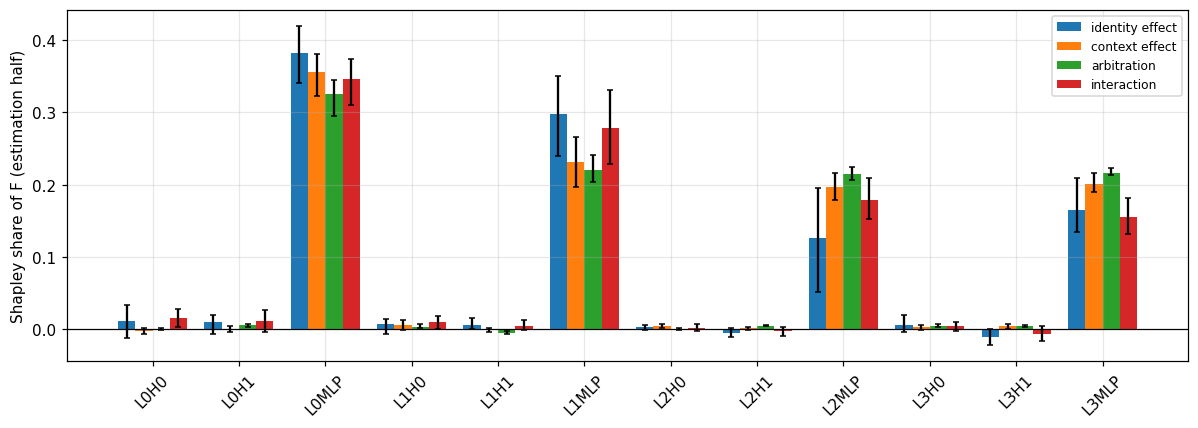

In [18]:
from math import factorial
N = N_COMPONENTS
SHAPLEY_WEIGHTS = np.zeros((N, len(MASKS)))
for i in range(N):
    bit = 1 << i
    for mask in MASKS:
        if mask & bit:
            continue
        size = bin(int(mask)).count("1")
        weight = factorial(size) * factorial(N - size - 1) / factorial(N)
        SHAPLEY_WEIGHTS[i, mask] -= weight
        SHAPLEY_WEIGHTS[i, mask | bit] += weight

shapley_rows = []
PHI_DRAWS = {behaviour: F_DRAWS[behaviour] @ SHAPLEY_WEIGHTS.T for behaviour in BEHAVIOURS_EXT}
for behaviour in BEHAVIOURS_EXT:
    phi = SHAPLEY_WEIGHTS @ F_POINT[behaviour]
    for i, component in enumerate(ALL):
        shapley_rows.append({"component": component, "behaviour": behaviour, "Shapley": phi[i],
                             "CI low": float(np.nanpercentile(PHI_DRAWS[behaviour][:, i], 2.5)),
                             "CI high": float(np.nanpercentile(PHI_DRAWS[behaviour][:, i], 97.5))})
shapley = pd.DataFrame(shapley_rows)
sums = shapley.groupby("behaviour")["Shapley"].sum()
print("sum of Shapley values per behaviour (must be 1):", sums.round(6).to_dict())
assert np.allclose(sums.to_numpy(), 1.0, atol=1e-6), "BLOCKED: Shapley values do not add up to F(full) - F(empty)"

selectivity_rows = []
phi_id = SHAPLEY_WEIGHTS @ F_POINT["identity effect"]
phi_ctx = SHAPLEY_WEIGHTS @ F_POINT["context effect"]
difference_draws = PHI_DRAWS["identity effect"] - PHI_DRAWS["context effect"]
for i, component in enumerate(ALL):
    low, high = np.nanpercentile(difference_draws[:, i], [2.5, 97.5])
    label = "identity-dominant" if low > 0.05 else ("context-dominant" if high < -0.05 else "shared / not separable")
    selectivity_rows.append({"component": component, "Shapley identity": phi_id[i], "Shapley context": phi_ctx[i],
                             "identity - context": phi_id[i] - phi_ctx[i], "CI low": low, "CI high": high,
                             "Shapley arbitration": float((SHAPLEY_WEIGHTS @ F_POINT["arbitration"])[i]),
                             "Shapley interaction": float((SHAPLEY_WEIGHTS @ F_POINT["interaction"])[i]),
                             "reading (plan rule)": label})
selectivity = pd.DataFrame(selectivity_rows)
shapley.to_csv(OUT / "results" / "MB14_shapley.csv", index=False)
selectivity.to_csv(OUT / "results" / "MB14_shapley_selectivity.csv", index=False)
print(selectivity.round(4).to_string(index=False))

fig, axis = plt.subplots(figsize=(11, 4))
width = 0.2
for k, behaviour in enumerate(BEHAVIOURS_EXT):
    block = shapley[shapley.behaviour == behaviour]
    axis.bar(np.arange(N) + (k - 1.5) * width, block["Shapley"], width, label=behaviour,
             yerr=[block["Shapley"] - block["CI low"], block["CI high"] - block["Shapley"]], capsize=2)
axis.set_xticks(np.arange(N)); axis.set_xticklabels(ALL, rotation=45); axis.axhline(0, color="black", linewidth=0.8)
axis.set_ylabel("Shapley share of F (estimation half)"); axis.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB14_shapley.png", bbox_inches="tight"); plt.show()

**How to read the Shapley table.** A row with a large identity share and a small context share would be a component that matters for the player but not for the situation. If every component has similar shares for both behaviours, the components do not divide the work between identity and context; the work is shared at this grain. Shapley values say how much a component contributes *on average over orders of adding components*; they do not say that the component is used in the same way for both behaviours (that is MB17's question).

## 12. Separability circuits

On the discovery half, the subset with the largest F(identity) − F(context) is chosen (S_id), and the subset with the largest F(context) − F(identity) (S_ctx). Both are scored on the estimation half. The optimum on the estimation half itself is printed only as a measure of how much the selection would flatter the result if it were chosen on the same data.

Reading rule (from the plan): separation is **found** for a signal if its subset has F(own) − F(other) with interval low > 0.25 and F(own) with interval low > 0.5. If neither passes, component-level separation is **tested and found absent**: no combination of heads and MLPs carries one signal without the other.

                                                                                                  0                                                1
circuit                                                             S_id (identity without context)                 S_ctx (context without identity)
components (chosen on discovery)                    L0H0+L0H1+L0MLP+L1H0+L1H1+L1MLP+L2H0+L3H0+L3MLP  L0H0+L0MLP+L1H0+L1H1+L2H0+L2H1+L2MLP+L3H1+L3MLP
size                                                                                              9                                                9
gap on discovery                                                                             0.2752                                           0.0963
F own (estimation)                                                                             0.98                                            0.616
F own CI low                                                                                 0.7648       

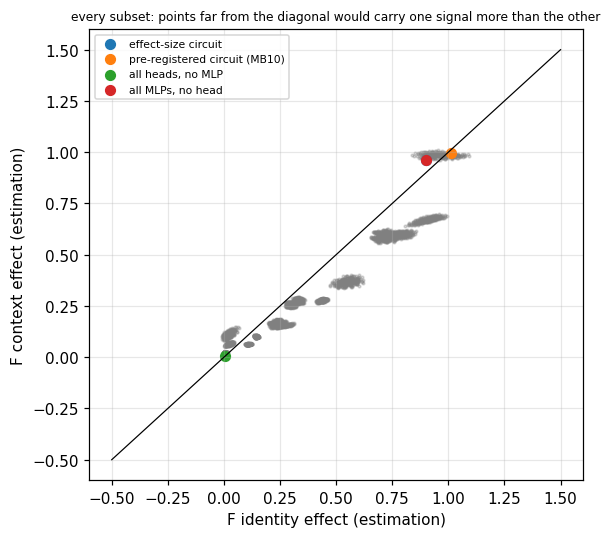

correlation of F(identity) and F(context) over all subsets: 0.9651


In [19]:
separability_rows = []
for own, other, label in [("identity effect", "context effect", "S_id (identity without context)"),
                          ("context effect", "identity effect", "S_ctx (context without identity)")]:
    gap_discovery = F["discovery"][own] - F["discovery"][other]
    chosen = int(np.nanargmax(gap_discovery))
    gap_estimation_point = F_POINT[own][chosen] - F_POINT[other][chosen]
    gap_draws = F_DRAWS[own][:, chosen] - F_DRAWS[other][:, chosen]
    own_low = float(np.nanpercentile(F_DRAWS[own][:, chosen], 2.5))
    gap_low, gap_high = np.nanpercentile(gap_draws, [2.5, 97.5])
    estimation_optimum = int(np.nanargmax(F_POINT[own] - F_POINT[other]))
    separability_rows.append({
        "circuit": label, "components (chosen on discovery)": "+".join(members(chosen)) or "(none)",
        "size": int(sizes[chosen]), "gap on discovery": float(gap_discovery[chosen]),
        "F own (estimation)": float(F_POINT[own][chosen]), "F own CI low": own_low,
        "F other (estimation)": float(F_POINT[other][chosen]),
        "gap (estimation)": float(gap_estimation_point), "gap CI low": gap_low, "gap CI high": gap_high,
        "separation found (plan rule)": bool(gap_low > 0.25 and own_low > 0.5),
        "best gap if chosen on estimation (optimistic)": float((F_POINT[own] - F_POINT[other])[estimation_optimum]),
        "that subset": "+".join(members(estimation_optimum)) or "(none)"})
separability = pd.DataFrame(separability_rows)
separability.to_csv(OUT / "results" / "MB14_separability.csv", index=False)
print(separability.round(4).T.to_string())
found = separability["separation found (plan rule)"].any()
print("\nComponent-level separation:", "FOUND for " + ", ".join(separability.loc[separability["separation found (plan rule)"], "circuit"])
      if found else "TESTED AND FOUND ABSENT (no subset of the 12 heads and MLPs carries one signal without the other)")

fig, axis = plt.subplots(figsize=(5.5, 5))
axis.scatter(F_POINT["identity effect"], F_POINT["context effect"], s=3, alpha=0.3, color="grey")
for name, components in NAMED.items():
    mask = mask_of(components)
    axis.scatter(F_POINT["identity effect"][mask], F_POINT["context effect"][mask], s=40, label=name)
axis.plot([-0.5, 1.5], [-0.5, 1.5], color="black", linewidth=0.8)
axis.set_xlabel("F identity effect (estimation)"); axis.set_ylabel("F context effect (estimation)")
axis.set_title("every subset: points far from the diagonal would carry one signal more than the other", fontsize=8)
axis.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB14_separability.png", bbox_inches="tight"); plt.show()
print("correlation of F(identity) and F(context) over all subsets:",
      round(float(np.corrcoef(F_POINT["identity effect"], F_POINT["context effect"])[0, 1]), 4))

## 13. Strata: genuine vs coupled events, frequent vs less frequent players

The named circuits' F and the Shapley values are recomputed on each stratum of the estimation half, from the same stored arrays (no new model runs). Strata with fewer than 30 events are reported as too small. Descriptive.

In [20]:
estimation_band = frequency_band(estimation["player"].to_numpy())
STRATA = {"genuine": estimation["genuine"].to_numpy().astype(bool),
          "coupled": ~estimation["genuine"].to_numpy().astype(bool)}
for band in np.unique(estimation_band):
    STRATA[band] = estimation_band == band
strata_rows, strata_shapley = [], []
for stratum, keep in STRATA.items():
    if keep.sum() < 30:
        strata_rows.append({"stratum": stratum, "events": int(keep.sum()), "note": "too small (< 30 events)"})
        continue
    for behaviour in BEHAVIOURS_EXT:
        point, draws = faithfulness_draws(scores["estimation"], behaviour, estimation, COUNTS, MATCH_POSITION, keep)
        phi = SHAPLEY_WEIGHTS @ point
        for name, components in NAMED.items():
            mask = mask_of(components)
            strata_rows.append({"stratum": stratum, "events": int(keep.sum()), "behaviour": behaviour, "circuit": name,
                                "F": float(point[mask]), "CI low": float(np.nanpercentile(draws[:, mask], 2.5)),
                                "CI high": float(np.nanpercentile(draws[:, mask], 97.5))})
        for i, component in enumerate(ALL):
            strata_shapley.append({"stratum": stratum, "behaviour": behaviour, "component": component, "Shapley": float(phi[i])})
strata_table = pd.DataFrame(strata_rows)
strata_shapley = pd.DataFrame(strata_shapley)
strata_table.to_csv(OUT / "results" / "MB14_strata_named.csv", index=False)
strata_shapley.to_csv(OUT / "results" / "MB14_strata_shapley.csv", index=False)
print(strata_table.round(4).to_string(index=False))
if len(strata_shapley):
    print(strata_shapley.pivot_table(index="component", columns=["behaviour", "stratum"], values="Shapley").round(3).to_string())

/tmp/ipykernel_11792/304978436.py:26: RuntimeWarning: invalid value encountered in divide
  draws = (counts @ top.T) / (counts @ bottom)[:, None]


                stratum  events       behaviour                       circuit       F  CI low  CI high
                genuine     282 identity effect           effect-size circuit  0.8970  0.7782   1.0214
                genuine     282 identity effect pre-registered circuit (MB10)  0.9938  0.9613   1.0215
                genuine     282 identity effect             all heads, no MLP  0.0080 -0.0062   0.0289
                genuine     282 identity effect             all MLPs, no head  0.8970  0.7782   1.0214
                genuine     282  context effect           effect-size circuit  1.0052  0.9582   1.0503
                genuine     282  context effect pre-registered circuit (MB10)  1.0064  0.9915   1.0204
                genuine     282  context effect             all heads, no MLP  0.0060 -0.0029   0.0141
                genuine     282  context effect             all MLPs, no head  1.0052  0.9582   1.0503
                genuine     282     arbitration           effect-size cir

## 14. What these additions can and cannot show

- Shapley values and separability circuits are about **whole heads and MLP blocks**. "Tested and found absent" here means no combination of these blocks separates the two signals. It does not rule out separate identity and context **directions inside** the same MLPs; MB17 tests that.
- The interaction behaviour uses one donor context per event (the MB02 donor). A different context contrast could load on different components.

In [21]:
extension_summary = {"plan": "MB14_ext", "interaction_named": interaction_named.to_dict(orient="records"),
                     "shapley_selectivity": selectivity.to_dict(orient="records"),
                     "separability": separability.to_dict(orient="records"),
                     "strata_named": strata_table.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB14_ext_summary.json", extension_summary)
fingerprint.record_files(MANIFEST, {"results/MB14_ext_summary.json": OUT / "results" / "MB14_ext_summary.json"})

{'artifacts/conflict/conflict_set.parquet': {'path': 'artifacts/conflict/conflict_set.parquet',
  'bytes': 1735548,
  'sha256': '19d6197298f38803450ba3befbc0e1b744b6ab900eecb0f6374783c4cf2263b3',
  'recorded_at': '2026-10-05T17:22:56.743259+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt',
  'bytes': 330757,
  'sha256': '590fbc131586f5297fcd9ddfcdf7f2e1c503cf13e9f584142a5c31a10a79339c',
  'recorded_at': '2026-10-05T17:22:56.743711+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt',
  'bytes': 2280753,
  'sha256': 'eab81928ab7743ddbe2cbdb1dc60d5b584408386e896705115145e7c8a6d62a2',
  'recorded_at': '2026-10-05T17:22:56.746435+00:00'},
 'artifacts/conflict/predictions/test_probs.parquet': {'path': 'artifacts/conflict/predictions/test_probs.parquet',
  'bytes': 7982855,
  'sha256': 'd21c146acd76ee17cb82670b

## 15. Summary and integrity

In [22]:
summary = {"status": PLAN["status"], "effect_size_circuit": EFFECT_CIRCUIT, "preregistered_circuit": PREREG_CIRCUIT,
           "named": named.to_dict(orient="records"), "best_by_size": best.to_dict(orient="records"),
           "minimality": minimality.to_dict(orient="records"), "resample_check": resample_check.to_dict(orient="records"),
           "specificity": specificity.to_dict(orient="records"), "replication": replication.to_dict(orient="records"),
           "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB14_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB14_summary.json": OUT / "results" / "MB14_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB14", "experiment": "effect-size circuit and exhaustive subset faithfulness",
                                "seed": PRIMARY_SEED, "subsets": int(len(MASKS)), "run_mode": RUN_MODE})
eff = named[named.circuit == "effect-size circuit"]
for _, row in eff.iterrows():
    sufficient = row["F CI low"] > 0.8
    distinctive = row["percentile among same size"] > 95
    print(f"{row['behaviour']:16s} F {row['F']:.3f} [{row['F CI low']:.3f}, {row['F CI high']:.3f}] | "
          f"percentile among {row['same-size circuits']} same-size circuits {row['percentile among same size']:.1f} | "
          f"sufficient: {sufficient} | distinctive: {distinctive}")

identity effect  F 0.901 [0.831, 1.012] | percentile among 495 same-size circuits 99.8 | sufficient: True | distinctive: True
arbitration      F 0.965 [0.953, 0.974] | percentile among 495 same-size circuits 99.8 | sufficient: True | distinctive: True
context effect   F 0.960 [0.941, 0.983] | percentile among 495 same-size circuits 99.8 | sufficient: True | distinctive: True


In [23]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 82
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: